# Wykrywanie uszkodzeń obiektów budowlanych – segmentacja pęknięć (CrackVision12K)

In [1]:
#conda create -n cracks python=3.12 -y
#conda activate cracks

#pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cu134


#pip install segmentation-models-pytorch "albumentations==2.0.8" opencv-python pandas matplotlib tqdm ipykernel ipywidgets

#python -c "import torch; print(torch.__version__, torch.cuda.is_available())"

## 0. Importy i urządzenie

In [2]:
import os
import json
import time
import random
import platform
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {platform.python_version()} | torch {torch.__version__} | smp {smp.__version__} | albumentations {A.__version__}")
print(f"Urządzenie: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))

Python 3.12.16 | torch 2.15.0+cu134 | smp 0.6.0 | albumentations 2.0.8
Urządzenie: cuda (NVIDIA GeForce RTX 4060 Ti)


## 1. Konfiguracja eksperymentu

In [ ]:
DATA_DIR = Path("CrackVision12K/split_dataset_final")
TRAIN_IMG_DIR, TRAIN_MASK_DIR = DATA_DIR / "train" / "IMG", DATA_DIR / "train" / "GT"
VAL_IMG_DIR,   VAL_MASK_DIR   = DATA_DIR / "val"   / "IMG", DATA_DIR / "val"   / "GT"
TEST_IMG_DIR,  TEST_MASK_DIR  = DATA_DIR / "test"  / "IMG", DATA_DIR / "test"  / "GT"

MAX_TRAIN_IMAGES = None   # None = cały zbiór treningowy
MAX_VAL_IMAGES   = None
MAX_TEST_IMAGES  = None

# wyniki
OUT_DIR  = Path("results")
CKPT_DIR = OUT_DIR / "checkpoints"
HIST_DIR = OUT_DIR / "histories"
FIG_DIR  = OUT_DIR / "figures"
for d in (CKPT_DIR, HIST_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# konfig. 1
SEED            = 42
IMG_SIZE        = 256
EPOCHS          = 10
BATCH_SIZE      = 16
LR              = 3e-4          # Adam
ENCODER         = "resnet18"
ENCODER_WEIGHTS = "imagenet"    
THRESHOLD       = 0.5           # próg binaryzacji predykcji

# eksperymenty
ARCHS   = ["U-Net", "DeepLabV3+", "FPN"]
CONFIGS = {"Konf 1": False,     
           "Konf 2": True}      # konfg. 2 posiada augmentację

FORCE_RETRAIN = False
NUM_WORKERS = 0 if platform.system() == "Windows" else min(4, os.cpu_count() or 1)
PIN_MEMORY  = device.type == "cuda"
USE_AMP     = device.type == "cuda"

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

## 2. Powtarzalność (seed)

In [ ]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)
    info = torch.utils.data.get_worker_info()
    tf = getattr(info.dataset, "transform", None)
    if tf is not None and hasattr(tf, "set_random_seed"):
        tf.set_random_seed(s)


set_seed()

## 3. Dane: pary obraz–maska, transformacje, Dataset

In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def list_pairs(img_dir: Path, mask_dir: Path, max_items=None, seed=SEED):
    imgs  = {p.stem: p for p in Path(img_dir).iterdir()  if p.suffix.lower() in IMG_EXT}
    masks = {p.stem: p for p in Path(mask_dir).iterdir() if p.suffix.lower() in IMG_EXT}
    common = sorted(imgs.keys() & masks.keys())
    no_mask, no_img = sorted(imgs.keys() - masks.keys()), sorted(masks.keys() - imgs.keys())
    if no_mask or no_img:
        print(f"Error. {img_dir.parent.name}: {len(no_mask)} obrazów bez maski, {len(no_img)} masek bez obrazu. "
              f"Przykłady: {no_mask[:3]} / {no_img[:3]}")
    assert common, f"Error. Brak dopasowanych par w {img_dir} i {mask_dir} Sprawdź ścieżki i nazwy plików."
    pairs = [(imgs[k], masks[k]) for k in common]
    if max_items is not None and max_items < len(pairs):
        rng = np.random.default_rng(seed)
        idx = sorted(rng.choice(len(pairs), size=max_items, replace=False))
        pairs = [pairs[i] for i in idx]
    return pairs


def imread_any(path: Path, flags=cv2.IMREAD_COLOR):
    # cv2.imread nie obsługuje polskich znaków w ścieżkach na Windows -> imdecode
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, flags)
    if img is None:
        raise IOError(f"Nie można wczytać: {path}")
    return img


def load_mask(path: Path):
    m = imread_any(path, cv2.IMREAD_GRAYSCALE)
    # maski zapisane jako 0/255 lub 0/1
    return (m > 127 if m.max() > 1 else m > 0).astype(np.float32)


def make_transform(augment: bool):
    tfs = [A.Resize(IMG_SIZE, IMG_SIZE)]   # maska skalowana metodą nearest neighbour
    if augment:
        tfs += [A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5)]
    tfs += [A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()]
    return A.Compose(tfs, seed=SEED)


class CrackDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        image = cv2.cvtColor(imread_any(img_path), cv2.COLOR_BGR2RGB)
        mask = load_mask(mask_path)
        out = self.transform(image=image, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float()


train_pairs = list_pairs(TRAIN_IMG_DIR, TRAIN_MASK_DIR, MAX_TRAIN_IMAGES)
val_pairs   = list_pairs(VAL_IMG_DIR,   VAL_MASK_DIR,   MAX_VAL_IMAGES)
test_pairs  = list_pairs(TEST_IMG_DIR,  TEST_MASK_DIR,  MAX_TEST_IMAGES)
print(f"Train: {len(train_pairs)} | Val: {len(val_pairs)} | Test: {len(test_pairs)}")

Train: 9600 | Val: 1200 | Test: 1200


### Przegląd zbioru

Rozmiary oryginalnych obrazów (próbka 300): [(256, 256)]
Średni udział pikseli pęknięć: 6.21% (mediana 3.52%)
Maski bez pęknięć w próbce: 60/300


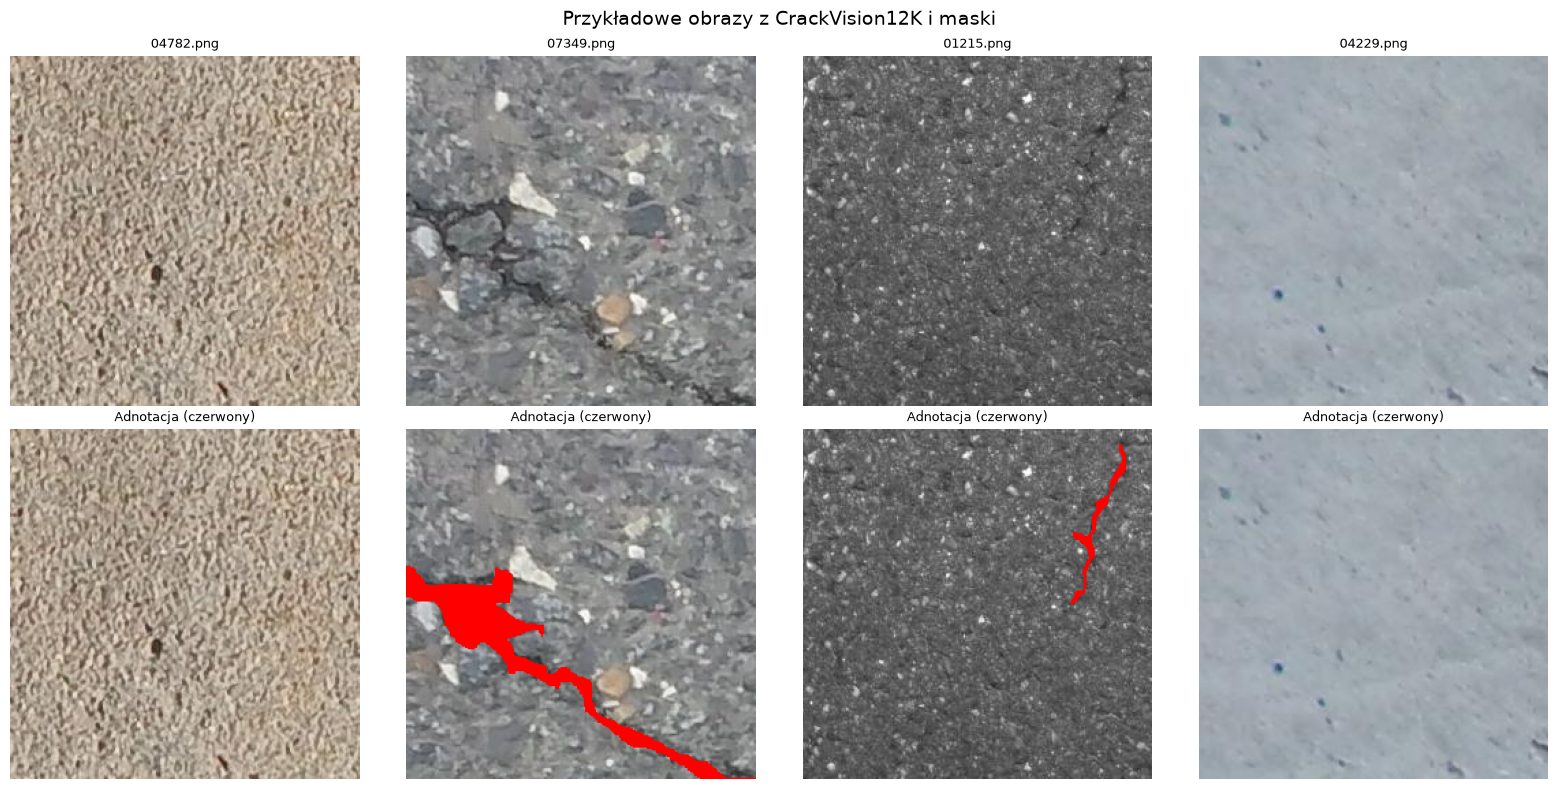

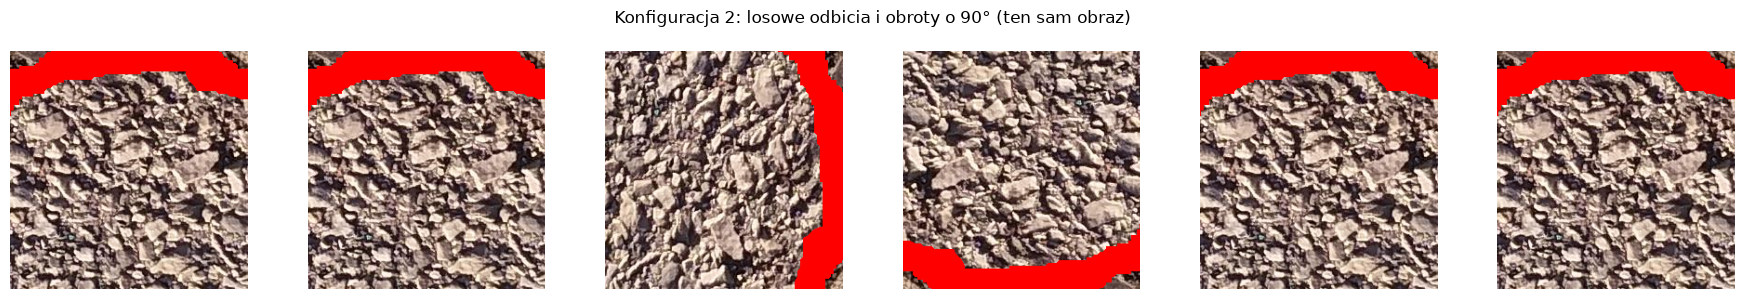

In [6]:
rng = np.random.default_rng(SEED)
probe = [train_pairs[i] for i in rng.choice(len(train_pairs), size=min(300, len(train_pairs)), replace=False)]
sizes, crack_frac, empty = set(), [], 0
for ip, mp in probe:
    m = load_mask(mp)
    sizes.add(m.shape)
    crack_frac.append(m.mean())
    empty += m.sum() == 0
print(f"Rozmiary oryginalnych obrazów (próbka {len(probe)}): {sorted(sizes)[:5]}")
print(f"Średni udział pikseli pęknięć: {100*np.mean(crack_frac):.2f}% (mediana {100*np.median(crack_frac):.2f}%)")
print(f"Maski bez pęknięć w próbce: {empty}/{len(probe)}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, (ip, mp) in enumerate(probe[:4]):
    img = cv2.cvtColor(imread_any(ip), cv2.COLOR_BGR2RGB)
    m = load_mask(mp)
    axes[0, col].imshow(img); axes[0, col].set_title(ip.name, fontsize=9)
    over = img.copy(); over[m > 0] = (255, 0, 0)
    axes[1, col].imshow(over); axes[1, col].set_title("Adnotacja (czerwony)", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Przykładowe obrazy z CrackVision12K i maski", fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR / "dataset_examples.png", dpi=150); plt.show()

# Podgląd augmentacji (Konf 2) na jednym obrazie
aug_ds = CrackDataset(train_pairs[:1], make_transform(True))
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax in axes:
    im, mk = aug_ds[0]
    im = np.clip(im.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    im[mk[0].numpy() > 0] = (1, 0, 0)
    ax.imshow(im); ax.axis("off")
plt.suptitle("Konfiguracja 2: losowe odbicia i obroty o 90° (ten sam obraz)")
plt.tight_layout(); plt.savefig(FIG_DIR / "augmentation_examples.png", dpi=150); plt.show()

## 4. Model, funkcja straty, metryki

In [7]:
ARCH_CLASSES = {"U-Net": smp.Unet, "DeepLabV3+": smp.DeepLabV3Plus, "FPN": smp.FPN}


def build_model(arch: str):
    return ARCH_CLASSES[arch](encoder_name=ENCODER, encoder_weights=ENCODER_WEIGHTS,
                              in_channels=3, classes=1)


class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = smp.losses.DiceLoss(mode="binary", from_logits=True)

    def forward(self, logits, target):
        return self.bce(logits, target) + self.dice(logits, target)


def metrics_from_counts(tp, fp, fn, eps=1e-7):
    return {"iou": tp / (tp + fp + fn + eps),
            "f1": 2 * tp / (2 * tp + fp + fn + eps),
            "precision": tp / (tp + fp + eps),
            "recall": tp / (tp + fn + eps)}


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    tp = fp = fn = 0.0
    loss_sum, n = 0.0, 0
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(images)
        logits = logits.float()
        if criterion is not None:
            loss_sum += criterion(logits, masks).item() * images.size(0)
            n += images.size(0)
        preds = (torch.sigmoid(logits) > THRESHOLD).float()
        tp += (preds * masks).sum().item()
        fp += (preds * (1 - masks)).sum().item()
        fn += ((1 - preds) * masks).sum().item()
    out = metrics_from_counts(tp, fp, fn)
    if criterion is not None:
        out["loss"] = loss_sum / max(n, 1)
    return out


def count_params(model):
    return sum(p.numel() for p in model.parameters())

## 5. Trening

In [8]:
def make_loader(pairs, augment: bool, shuffle: bool):
    g = torch.Generator()
    g.manual_seed(SEED)              # ta sama kolejność batchy dla wszystkich architektur
    return DataLoader(CrackDataset(pairs, make_transform(augment)),
                      batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                      worker_init_fn=seed_worker if NUM_WORKERS > 0 else None,
                      generator=g)


def train_one_epoch(model, loader, criterion, optimizer, scaler, desc=""):
    model.train()
    total, n = 0.0, 0
    for images, masks in tqdm(loader, desc=desc, leave=False):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(images)
        loss = criterion(logits.float(), masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * images.size(0)
        n += images.size(0)
    return total / max(n, 1)


def slug(name):
    return name.replace(" ", "_").replace("+", "plus")


def run_experiment(arch, conf_name, augment, train_pairs, val_loader, epochs=EPOCHS):
    name = f"{arch} {conf_name}"
    ckpt_path, hist_path = CKPT_DIR / f"{slug(name)}.pth", HIST_DIR / f"{slug(name)}.json"
    if not FORCE_RETRAIN and ckpt_path.exists() and hist_path.exists():
        print(f"[POMIJAM] {name} – wynik już istnieje ({hist_path})")
        return json.loads(hist_path.read_text(encoding="utf-8"))

    print(f"\n=== {name} | augmentacja: {augment} ===")
    set_seed(SEED)                                 # identyczna inicjalizacja dekodera i kolejność danych
    model = build_model(arch).to(device)
    criterion = BCEDiceLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    train_loader = make_loader(train_pairs, augment=augment, shuffle=True)

    hist = {"name": name, "arch": arch, "config": conf_name, "augment": augment,
            "n_params": count_params(model), "epochs": epochs,
            "train_loss": [], "val_loss": [], "val_iou": [], "val_f1": [],
            "val_precision": [], "val_recall": [], "epoch_time_s": []}
    best_iou, best_epoch = -1.0, 0
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, desc=f"{name} ep{epoch}")
        val = evaluate(model, val_loader, criterion)
        dt = time.time() - t0
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(val["loss"])
        for k in ("iou", "f1", "precision", "recall"):
            hist[f"val_{k}"].append(val[k])
        hist["epoch_time_s"].append(dt)
        mark = ""
        if val["iou"] > best_iou:
            best_iou, best_epoch = val["iou"], epoch
            torch.save(model.state_dict(), ckpt_path)
            mark = "  <- zapisano najlepszy"
        print(f"Epoka {epoch:2d}/{epochs} | train loss {tr_loss:.4f} | val loss {val['loss']:.4f} | "
              f"val IoU {val['iou']:.4f} | val F1 {val['f1']:.4f} | {dt:.0f}s{mark}")

    hist.update(best_val_iou=best_iou, best_epoch=best_epoch, train_time_s=time.time() - t_start)
    hist_path.write_text(json.dumps(hist, indent=2), encoding="utf-8")
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return hist


val_loader  = make_loader(val_pairs,  augment=False, shuffle=False)
test_loader = make_loader(test_pairs, augment=False, shuffle=False)

## 6. Budżet obliczeniowy – pomiar czasu na małej próbce

In [9]:
N_PROBE = min(100, len(train_pairs))
probe_loader = make_loader(train_pairs[:N_PROBE], augment=True, shuffle=True)
probe_val    = make_loader(val_pairs[:N_PROBE],  augment=False, shuffle=False)

timing = []
for arch in ARCHS:
    set_seed()
    m = build_model(arch).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    sc = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    crit = BCEDiceLoss()
    for rep in range(2):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        train_one_epoch(m, probe_loader, crit, opt, sc, desc=f"pomiar {arch}")
        if device.type == "cuda": torch.cuda.synchronize()
        t_train = time.time() - t0
        t0 = time.time(); evaluate(m, probe_val); t_val = time.time() - t0
    per_img_train, per_img_val = t_train / N_PROBE, t_val / max(1, min(N_PROBE, len(val_pairs)))
    epoch_s = per_img_train * len(train_pairs) + per_img_val * len(val_pairs)
    timing.append({"Architektura": arch, "Parametry [M]": count_params(m) / 1e6,
                   "Czas / 100 obrazów [s]": t_train * 100 / N_PROBE,
                   "Szac. epoka [min]": epoch_s / 60,
                   "Szac. 2 konfiguracje [h]": 2 * EPOCHS * epoch_s / 3600})
    del m
    if device.type == "cuda": torch.cuda.empty_cache()

df_timing = pd.DataFrame(timing)
display(df_timing.round(3))
print(f"Szacowany łączny czas 6 treningów ({EPOCHS} epok, {len(train_pairs)} obrazów treningowych): "
      f"{df_timing['Szac. 2 konfiguracje [h]'].sum():.2f} h")
df_timing.to_csv(OUT_DIR / "timing_estimate.csv", index=False)

pomiar U-Net:   0%|          | 0/7 [00:00<?, ?it/s]

pomiar U-Net:   0%|          | 0/7 [00:00<?, ?it/s]

pomiar DeepLabV3+:   0%|          | 0/7 [00:00<?, ?it/s]

pomiar DeepLabV3+:   0%|          | 0/7 [00:00<?, ?it/s]

pomiar FPN:   0%|          | 0/7 [00:00<?, ?it/s]

pomiar FPN:   0%|          | 0/7 [00:00<?, ?it/s]

,Architektura,Parametry [M],Czas / 100 obrazów [s],Szac. epoka [min],Szac. 2 konfiguracje [h]
0,U-Net,14.328,0.712,1.216,0.405
1,DeepLabV3+,12.329,0.561,0.966,0.322
2,FPN,13.047,0.598,1.022,0.341


Szacowany łączny czas 6 treningów (10 epok, 9600 obrazów treningowych): 1.07 h


## 7. Główna pętla eksperymentów (6 treningów)

In [10]:
all_results = {}
for arch in ARCHS:
    for conf_name, augment in CONFIGS.items():
        h = run_experiment(arch, conf_name, augment, train_pairs, val_loader)
        all_results[h["name"]] = h


=== U-Net Konf 1 | augmentacja: False ===


U-Net Konf 1 ep1:   0%|          | 0/600 [00:00<?, ?it/s]

Epoka  1/10 | train loss 0.5993 | val loss 0.4137 | val IoU 0.5965 | val F1 0.7472 | 196s  <- zapisano najlepszy


U-Net Konf 1 ep2:   0%|          | 0/600 [00:00<?, ?it/s]

Epoka  2/10 | train loss 0.3956 | val loss 0.4000 | val IoU 0.5938 | val F1 0.7451 | 71s


U-Net Konf 1 ep3:   0%|          | 0/600 [00:00<?, ?it/s]

... (111 outputs left out)

FPN Konf 2 ep9:   0%|          | 0/600 [00:00<?, ?it/s]

Epoka  9/10 | train loss 0.3193 | val loss 0.3356 | val IoU 0.6470 | val F1 0.7856 | 59s


FPN Konf 2 ep10:   0%|          | 0/600 [00:00<?, ?it/s]

Epoka 10/10 | train loss 0.3150 | val loss 0.3375 | val IoU 0.6476 | val F1 0.7861 | 67s


## 8. Ewaluacja na zbiorze testowym

In [16]:
def load_trained(arch, conf_name):
    m = build_model(arch)
    state = torch.load(CKPT_DIR / f"{slug(f'{arch} {conf_name}')}.pth", map_location="cpu", weights_only=True)
    m.load_state_dict(state)
    return m.to(device).eval()


rows = []
for arch in ARCHS:
    for conf_name in CONFIGS:
        h = all_results[f"{arch} {conf_name}"]
        test = evaluate(load_trained(arch, conf_name), test_loader)
        rows.append({"Architektura": arch, "Konfiguracja": conf_name,
                     "Najlepsza epoka": h["best_epoch"],
                     "Val IoU": h["best_val_iou"],
                     "Test IoU": test["iou"], "Test F1 (Dice)": test["f1"],
                     "Test Precision": test["precision"], "Test Recall": test["recall"],
                     "Parametry [M]": h["n_params"] / 1e6,
                     "Czas treningu [min]": h["train_time_s"] / 60})
df_results = pd.DataFrame(rows)
df_results.to_csv(OUT_DIR / "results_test.csv", index=False)
display(df_results.round(4))

pivot = df_results.pivot(index="Architektura", columns="Konfiguracja", values="Test IoU").loc[ARCHS]
pivot["Δ (Konf 2 − Konf 1)"] = pivot["Konf 2"] - pivot["Konf 1"]
print("Test IoU i efekt augmentacji:")
display(pivot.round(4))

,Architektura,Konfiguracja,Najlepsza epoka,Val IoU,Test IoU,Test F1 (Dice),Test Precision,Test Recall,Parametry [M],Czas treningu [min]
0,U-Net,Konf 1,8,0.6372,0.6281,0.7716,0.7819,0.7616,14.3282,14.0661
1,U-Net,Konf 2,9,0.6443,0.6337,0.7758,0.7851,0.7666,14.3282,13.8901
2,DeepLabV3+,Konf 1,8,0.6314,0.6207,0.7660,0.7584,0.7737,12.3293,11.2129
3,DeepLabV3+,Konf 2,10,0.6435,0.6360,0.7775,0.7806,0.7745,12.3293,10.5997
4,FPN,Konf 1,10,0.6363,0.6304,0.7733,0.7614,0.7856,13.0472,9.4791
5,FPN,Konf 2,8,0.6534,0.6367,0.7780,0.8023,0.7552,13.0472,9.8829


Test IoU i efekt augmentacji:


Konfiguracja,Konf 1,Konf 2,Δ (Konf 2 − Konf 1)
Architektura,,,
U-Net,0.6281,0.6337,0.0055
DeepLabV3+,0.6207,0.6360,0.0153
FPN,0.6304,0.6367,0.0063


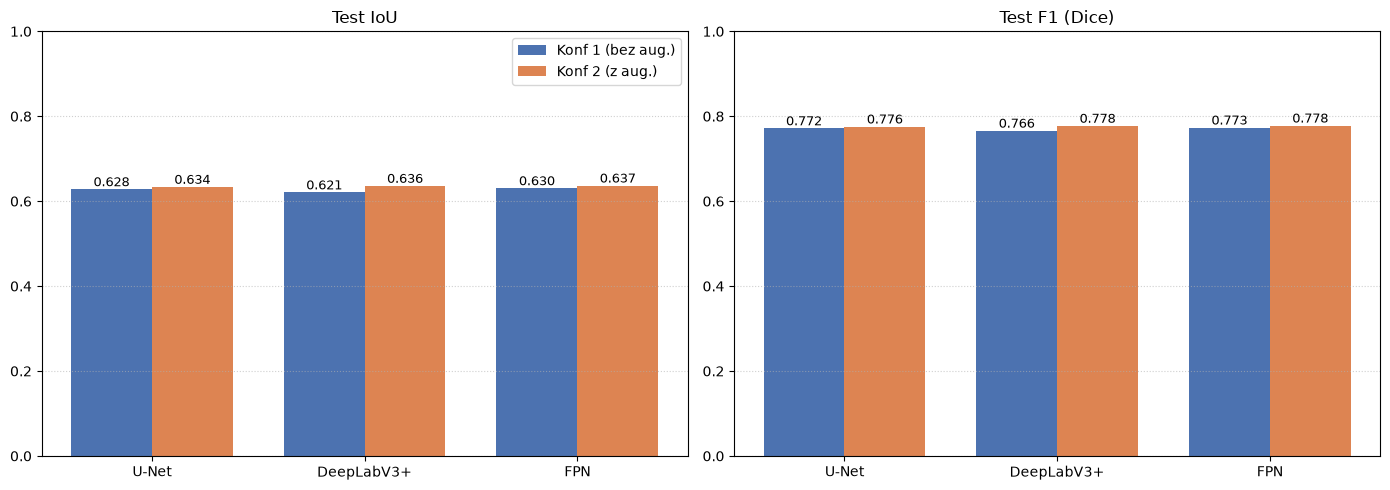

In [12]:
# Wykres słupkowy: Test IoU i Test F1 dla 6 treningów
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(ARCHS)); w = 0.38
for ax, metric in zip(axes, ["Test IoU", "Test F1 (Dice)"]):
    for i, (conf_name, color) in enumerate(zip(CONFIGS, ["#4C72B0", "#DD8452"])):
        vals = [df_results.loc[(df_results["Architektura"] == a) & (df_results["Konfiguracja"] == conf_name), metric].item()
                for a in ARCHS]
        bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f"{conf_name} ({'z aug.' if CONFIGS[conf_name] else 'bez aug.'})", color=color)
        ax.bar_label(bars, fmt="%.3f", fontsize=9)
    ax.set_xticks(x, ARCHS); ax.set_title(metric); ax.set_ylim(0, 1)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "test_metrics_bar.png", dpi=150); plt.show()

## 9. Krzywe uczenia

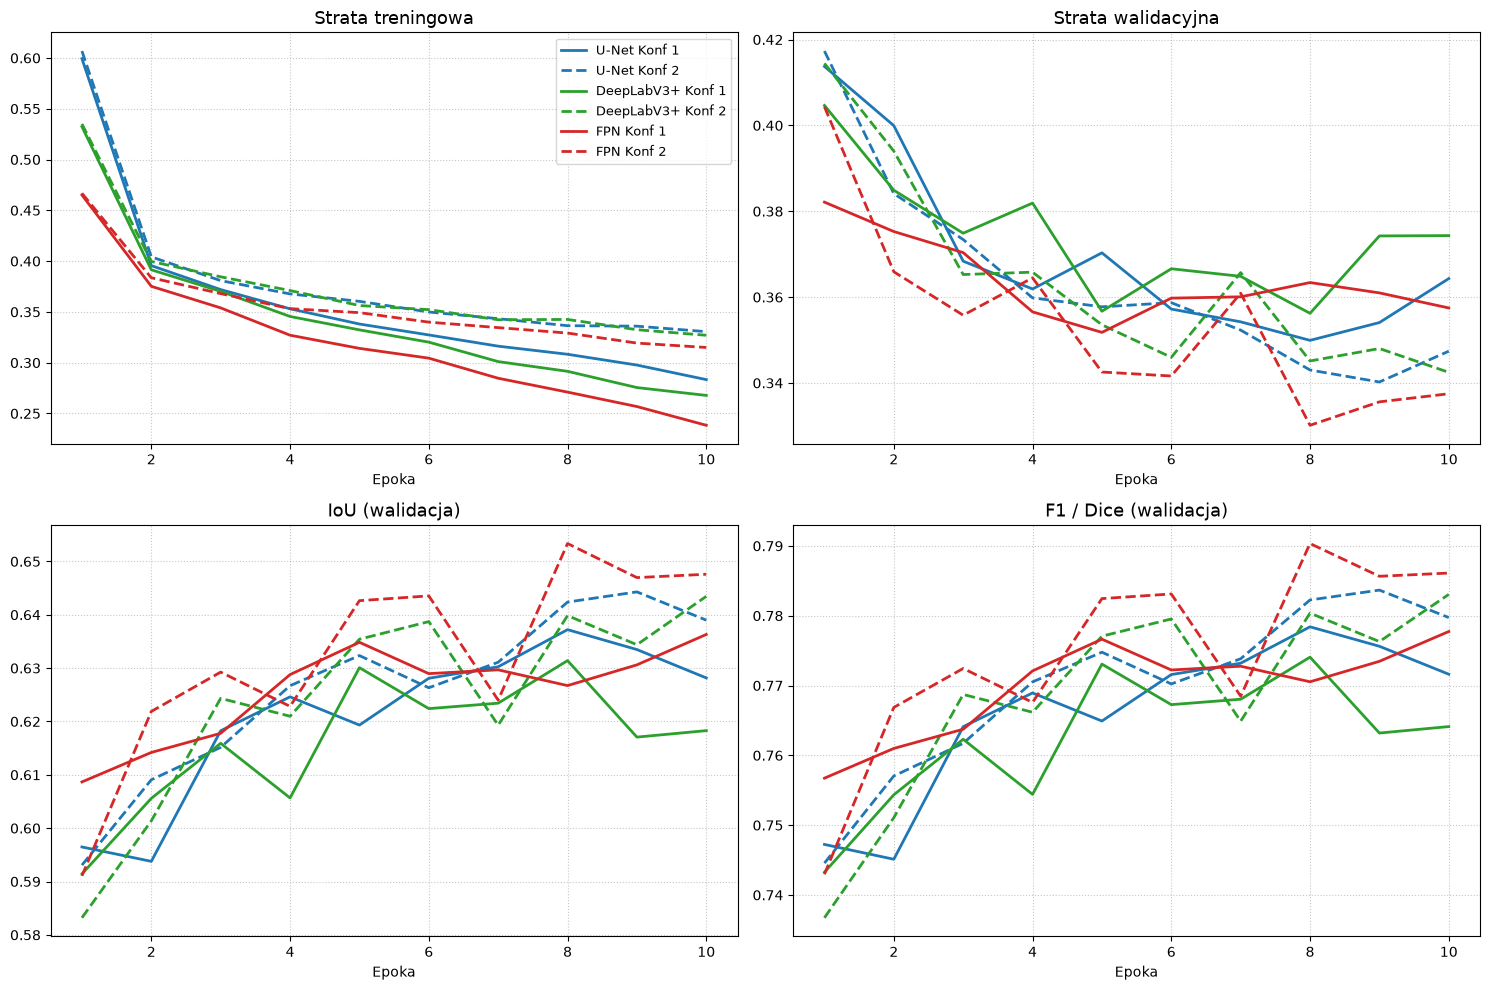

,Eksperyment,train loss,val loss,luka (val − train)
0,U-Net Konf 1,0.2833,0.3643,0.0810
1,U-Net Konf 2,0.3305,0.3474,0.0169
2,DeepLabV3+ Konf 1,0.2678,0.3743,0.1066
3,DeepLabV3+ Konf 2,0.3270,0.3425,0.0155
4,FPN Konf 1,0.2384,0.3575,0.1191
5,FPN Konf 2,0.3150,0.3375,0.0225


In [13]:
COLORS = {"U-Net": "tab:blue", "DeepLabV3+": "tab:green", "FPN": "tab:red"}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [("train_loss", "Strata treningowa"), ("val_loss", "Strata walidacyjna"),
          ("val_iou", "IoU (walidacja)"), ("val_f1", "F1 / Dice (walidacja)")]
for ax, (key, title) in zip(axes.ravel(), panels):
    for name, h in all_results.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], color=COLORS[h["arch"]],
                linestyle="--" if h["augment"] else "-", linewidth=2, label=name)
    ax.set_title(title, fontsize=13); ax.set_xlabel("Epoka"); ax.grid(True, linestyle=":", alpha=0.7)
axes[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curves.png", dpi=150); plt.show()

# Przeuczenie: różnica val_loss - train_loss w ostatniej epoce
gap = pd.DataFrame([{"Eksperyment": n, "train loss": h["train_loss"][-1], "val loss": h["val_loss"][-1],
                     "luka (val − train)": h["val_loss"][-1] - h["train_loss"][-1]} for n, h in all_results.items()])
display(gap.round(4))

## 10. Przykładowe predykcje

In [17]:
RUNS = [f"{a} {c}" for a in ARCHS for c in CONFIGS]
models = {name: load_trained(*name.split(" ", 1)) for name in RUNS}
test_ds = CrackDataset(test_pairs, make_transform(False))


@torch.no_grad()
def per_image_iou(model, loader):
    out = []
    for images, masks in loader:
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(images.to(device))
        preds = torch.sigmoid(logits.float()) > THRESHOLD
        masks = masks.to(device) > 0.5
        inter = (preds & masks).flatten(1).sum(1).float()
        union = (preds | masks).flatten(1).sum(1).float()
        iou = torch.where(union > 0, inter / union.clamp(min=1), torch.ones_like(union))  # oba puste = 1
        out.append(iou.cpu())
    return torch.cat(out).numpy()


iou_table = pd.DataFrame({name: per_image_iou(m, test_loader) for name, m in tqdm(models.items(), desc="IoU per obraz")})
iou_table["plik"] = [p[0].name for p in test_pairs]
iou_table["gt_pikseli"] = [int(load_mask(p[1]).sum()) for p in test_pairs]
iou_table.to_csv(OUT_DIR / "test_per_image_iou.csv", index=False)

has_crack = iou_table["gt_pikseli"] > 0
mean_iou, std_iou = iou_table[RUNS].mean(axis=1), iou_table[RUNS].std(axis=1)
best_idx  = mean_iou[has_crack].nlargest(2).index.tolist()
worst_idx = mean_iou[has_crack].nsmallest(3).index.tolist()
disag_idx = std_iou.drop(best_idx + worst_idx).nlargest(2).index.tolist()
print("Rozkład IoU per obraz (test):")
display(iou_table[RUNS].describe().T[["mean", "50%", "min", "max"]].round(3))

IoU per obraz:   0%|          | 0/6 [00:00<?, ?it/s]

Rozkład IoU per obraz (test):


,mean,50%,min,max
U-Net Konf 1,0.625,0.655,0.0,1.0
U-Net Konf 2,0.638,0.667,0.0,1.0
DeepLabV3+ Konf 1,0.611,0.661,0.0,1.0
DeepLabV3+ Konf 2,0.601,0.663,0.0,1.0
FPN Konf 1,0.624,0.667,0.0,1.0
FPN Konf 2,0.622,0.675,0.0,1.0


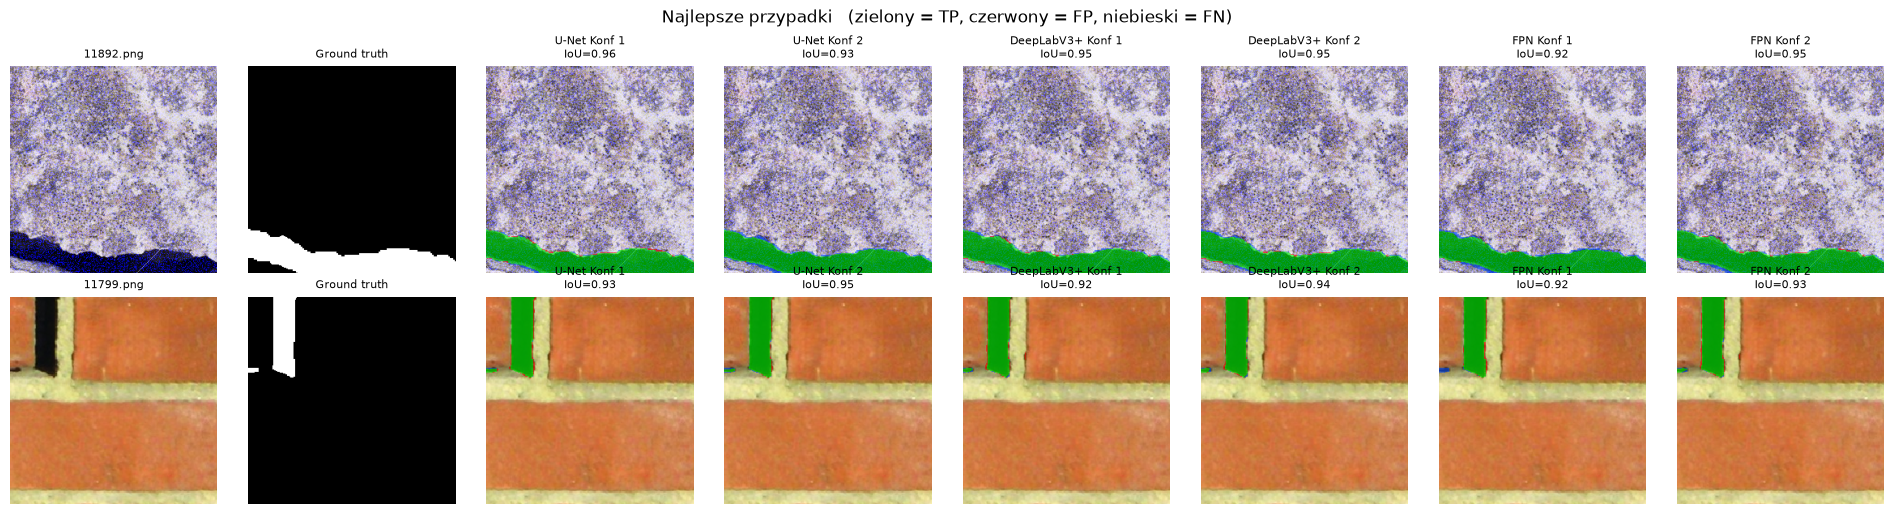

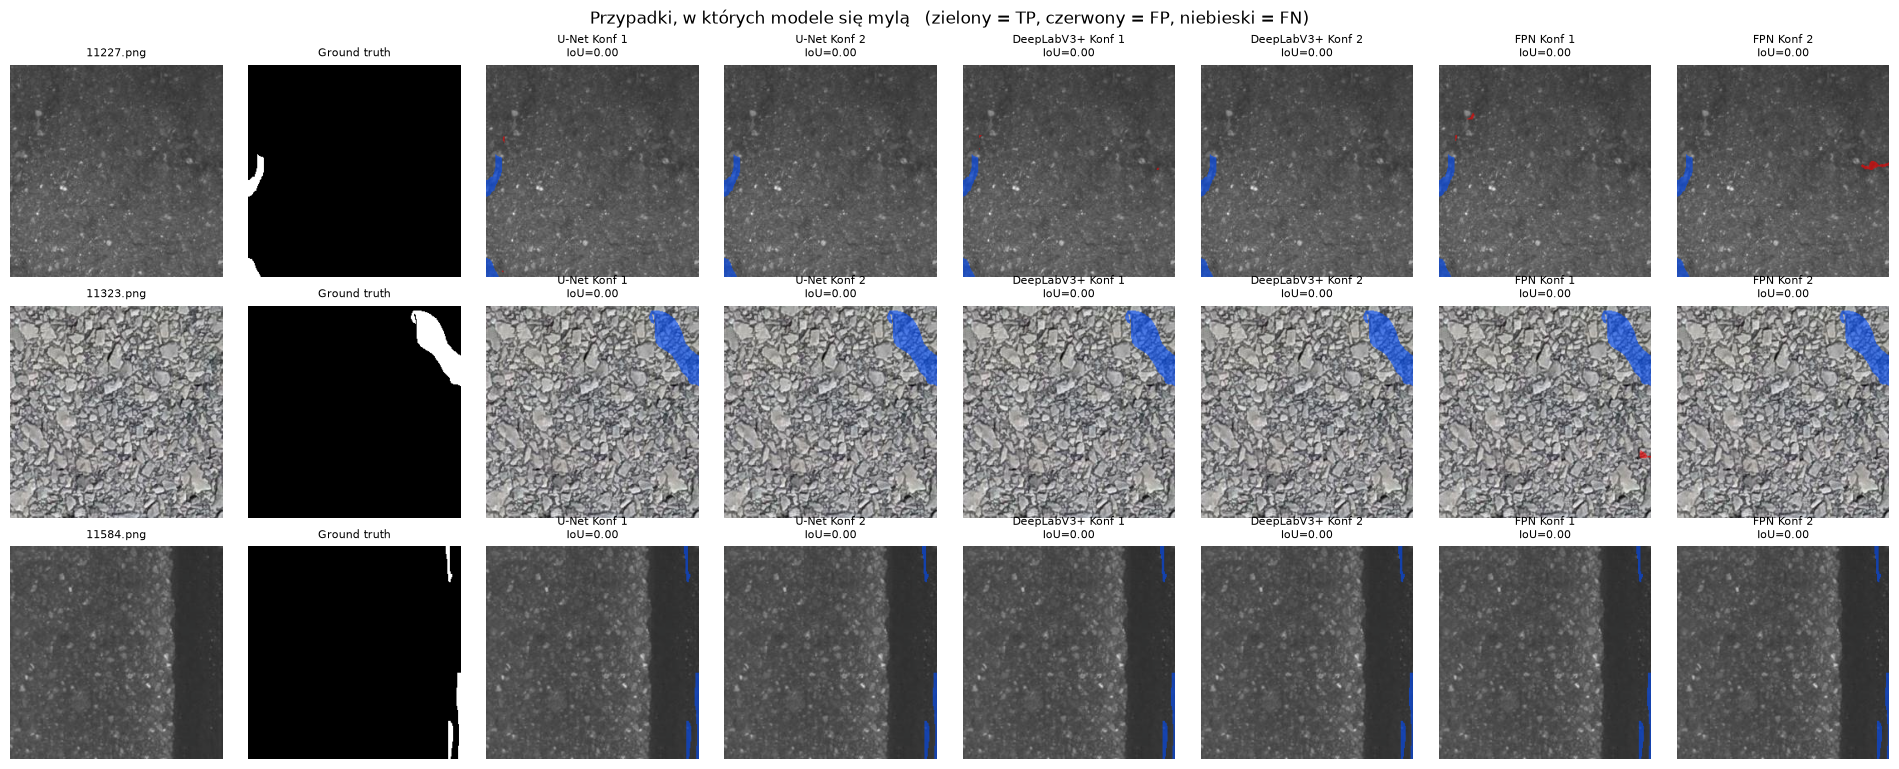

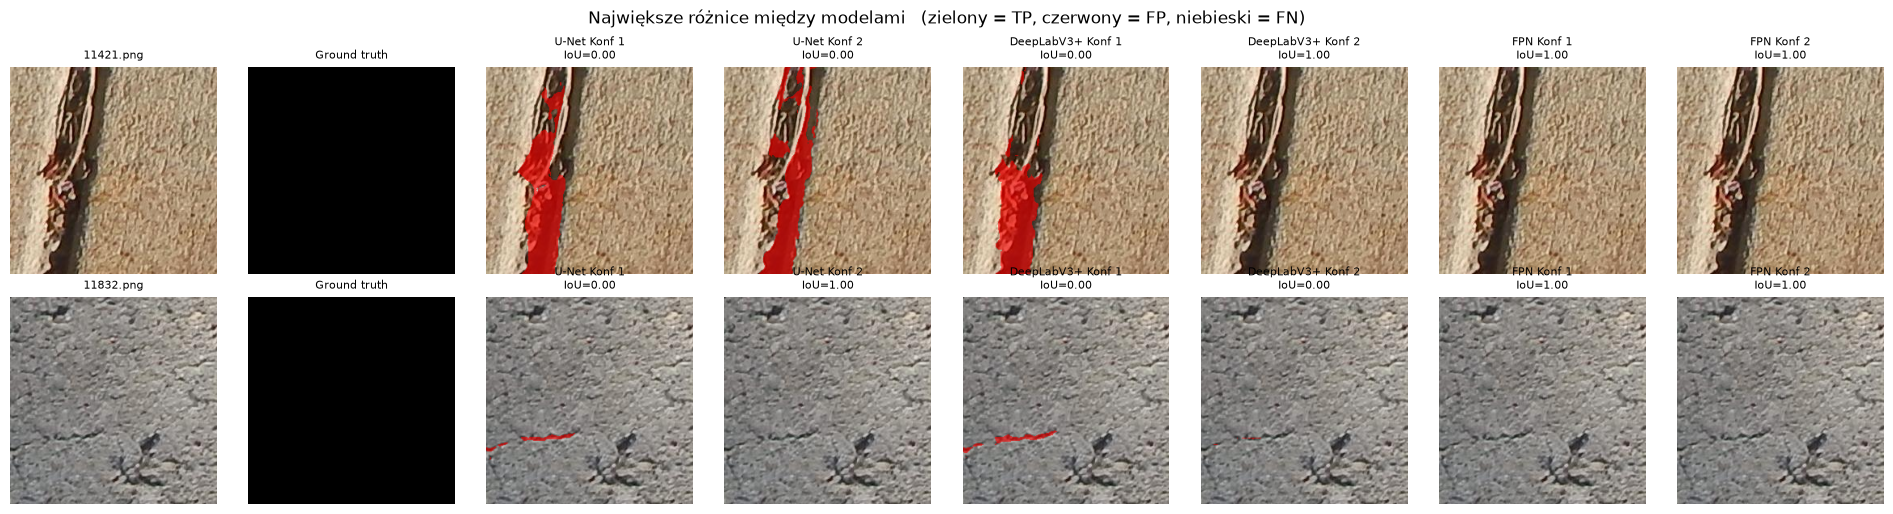

In [18]:
def denorm(t):
    return np.clip(t.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN, 0, 1)


def error_overlay(img, pred, gt):
    over = img.copy()
    tp, fp, fn = pred & gt, pred & ~gt, ~pred & gt
    over[tp] = 0.4 * over[tp] + 0.6 * np.array([0, 1, 0])
    over[fp] = 0.4 * over[fp] + 0.6 * np.array([1, 0, 0])
    over[fn] = 0.4 * over[fn] + 0.6 * np.array([0, 0.3, 1])
    return over


@torch.no_grad()
def show_predictions(indices, title, fname):
    ncol = 2 + len(RUNS)
    fig, axes = plt.subplots(len(indices), ncol, figsize=(2.4 * ncol, 2.6 * len(indices)), squeeze=False)
    for r, idx in enumerate(indices):
        img_t, mask_t = test_ds[idx]
        img, gt = denorm(img_t), mask_t[0].numpy() > 0.5
        axes[r, 0].imshow(img); axes[r, 0].set_title(test_pairs[idx][0].name[:22], fontsize=8)
        axes[r, 1].imshow(gt, cmap="gray"); axes[r, 1].set_title("Ground truth", fontsize=8)
        for c, name in enumerate(RUNS, start=2):
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logit = models[name](img_t.unsqueeze(0).to(device))
            pred = (torch.sigmoid(logit.float())[0, 0].cpu().numpy() > THRESHOLD)
            axes[r, c].imshow(error_overlay(img, pred, gt))
            axes[r, c].set_title(f"{name}\nIoU={iou_table.loc[idx, name]:.2f}", fontsize=8)
    for ax in axes.ravel():
        ax.axis("off")
    plt.suptitle(f"{title}   (zielony = TP, czerwony = FP, niebieski = FN)", fontsize=12)
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()


show_predictions(best_idx,  "Najlepsze przypadki", "pred_best.png")
show_predictions(worst_idx, "Przypadki, w których modele się mylą", "pred_worst.png")
show_predictions(disag_idx, "Największe różnice między modelami", "pred_disagreement.png")